In [2]:
import sys

import cv2
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm

import detection_utils

sys.path.append("../PG_PyTraining")
from common.pg import pg_geometry

%load_ext autoreload
%autoreload 2

In [3]:
def get_center(corners):
    return np.mean(corners, axis=0).astype(int)

def moving_average(x, w):
    return np.convolve(x, np.ones(w), 'valid') / w

def weighted_moving_average(x,y,step_size=0.05,width=1):
    bin_centers = np.arange(np.min(x),np.max(x)-0.5*step_size,step_size)+0.5*step_size
    bin_avg = np.zeros(len(bin_centers))

    def gaussian(x,amp=1,mean=0,sigma=1):
        return amp*np.exp(-(x-mean)**2/(2*sigma**2))

    for index in range(0,len(bin_centers)):
        bin_center = bin_centers[index]
        weights = gaussian(x,mean=bin_center,sigma=width)
        bin_avg[index] = np.average(y,weights=weights)

    return (bin_centers,bin_avg)

In [4]:
frames = []

cap = cv2.VideoCapture("2024-08-19-11-19-00/video01.avi")
while True:
    ret, frame = cap.read()
    if not ret:
        break
    frames.append(cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY))

cap.release()
len(frames)

1050

In [66]:
detector = detection_utils.ArucoDetector()
cam = pg_geometry.PgCamera(2650, "Cam3")

In [67]:
tmp = []
for frame in tqdm(frames):
    ids, _ = detector.detect(frame)
    if len(ids) != 5:
        continue
    tmp.append(frame)

len(tmp)

  0%|          | 0/440 [00:00<?, ?it/s]

100%|██████████| 440/440 [00:00<00:00, 441.59it/s]


440

In [68]:
frames = tmp

In [69]:
frame_size = (frames[0].shape[1], frames[0].shape[0])

# Initialize the video writer
fourcc = cv2.VideoWriter_fourcc(*'XVID')
out = cv2.VideoWriter("tmp.avi", fourcc, 5, frame_size)

for i, frame in enumerate(frames):
    tmp_frame = cv2.cvtColor(frame, cv2.COLOR_GRAY2BGR)
    # Overlay the frame index on the frame
    text = f"{i}"
    font = cv2.FONT_HERSHEY_SIMPLEX
    font_scale = 1
    color = (255, 255, 255)  # White color
    thickness = 2
    # Get text size to create a black background
    text_size = cv2.getTextSize(text, font, font_scale, thickness)[0]
    text_x = 10
    text_y = 10 + text_size[1]
    cv2.rectangle(tmp_frame, (text_x - 5, text_y - text_size[1] - 5), 
                    (text_x + text_size[0] + 5, text_y + 5), 
                    (0, 0, 0), -1)  # Black background
    cv2.putText(tmp_frame, text, (text_x, text_y), font, font_scale, color, thickness)

    # Write the frame to the video file
    out.write(tmp_frame)

out.release()

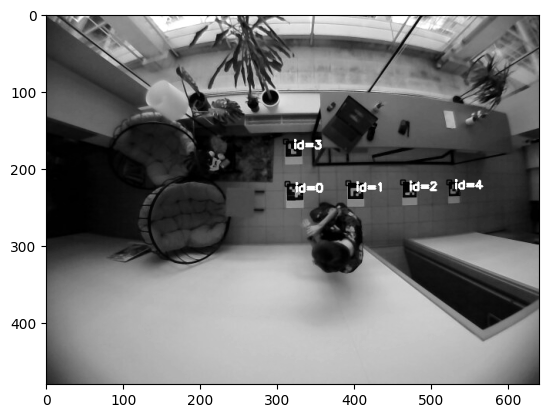

In [70]:
img_gray = frames[0]
corners, ids = detector.detect(img_gray)
len(ids)

tmp = img_gray.copy()
cv2.aruco.drawDetectedMarkers(tmp, corners, ids)
cv2.aruco.drawDetectedMarkers(tmp, corners, ids)
plt.imshow(tmp, cmap="gray")

In [71]:
gt_x_pos = [0, 100, 200, 0, 300]
gt_y_pos = [0, 0, 0, 75, 0]

In [72]:
data = []
for frame in tqdm(frames):
    # ids, corners, tvecs, rvecs, euler_rvecs = detector.estimate(tmp_frame)
    data.append(detector.estimate(frame))
    

ids, corners, tvecs, rvecs, euler_rvecs = list(zip(*data))
pos_vecs = np.array([cam.pixel2cm(np.mean(i, axis=(1, 2)).astype(int)) for i in corners])

euler_rvecs = np.array(euler_rvecs)

baseline_euler_rvecs = euler_rvecs[:, 0, :]

# fix roll
baseline_euler_rvecs[:, 0] = np.sign(baseline_euler_rvecs[:, 0]) * (180 - np.abs(baseline_euler_rvecs[:, 0]))

  0%|          | 0/440 [00:00<?, ?it/s]

100%|██████████| 440/440 [00:01<00:00, 366.31it/s]


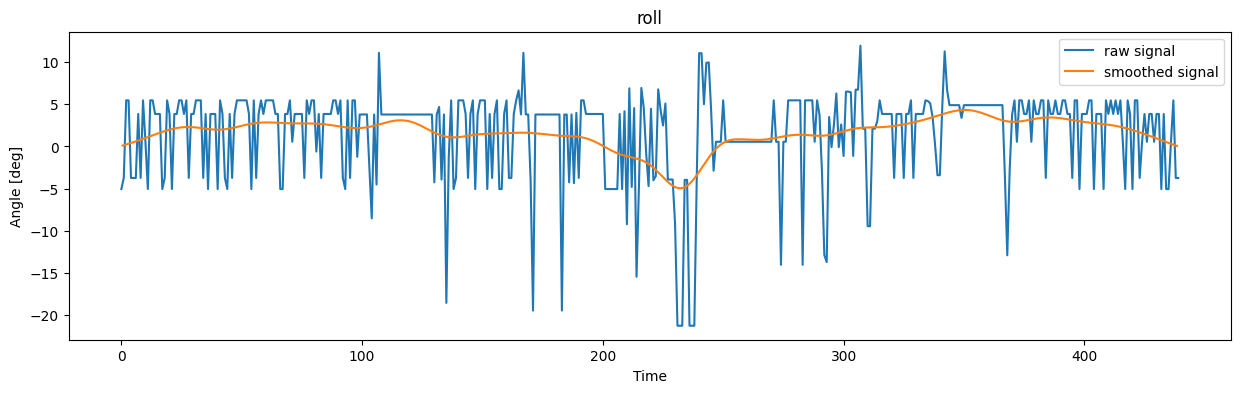

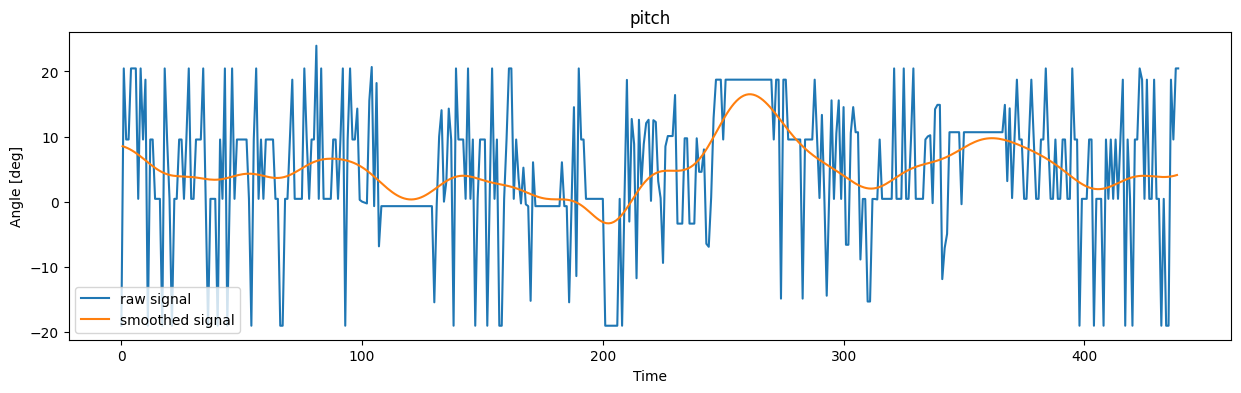

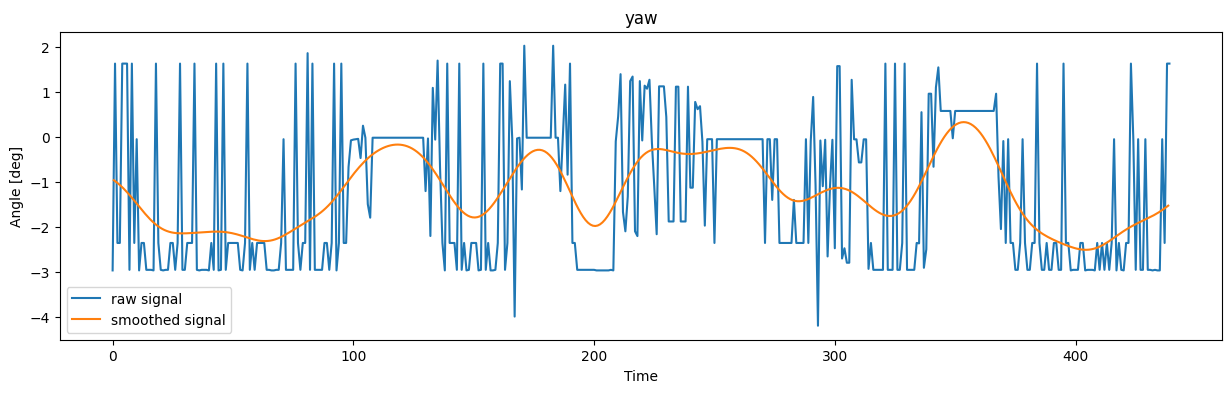

In [73]:
x_axis = np.arange(len(pos_vecs))


labels = ["roll", "pitch", "yaw"]
smoothed_rvecs = []
for i in range(3):
    x, y = weighted_moving_average(x_axis, baseline_euler_rvecs[:, i], step_size=1, width=9)
    smoothed_rvecs.append(y)

    plt.figure(figsize=(15, 4))
    plt.plot(x_axis, baseline_euler_rvecs[:,i], label="raw signal")
    plt.plot(x, y, label="smoothed signal")
    plt.legend()
    plt.xlabel("Time")
    plt.ylabel("Angle [deg]")
    plt.title(labels[i])

smoothed_rvecs = np.vstack(smoothed_rvecs).T

Text(0.5, 1.0, 'Markers position')

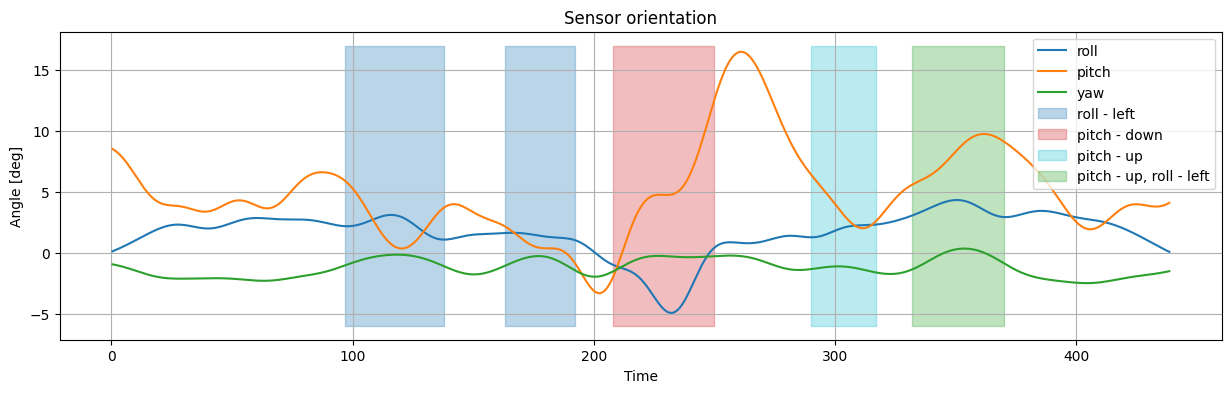

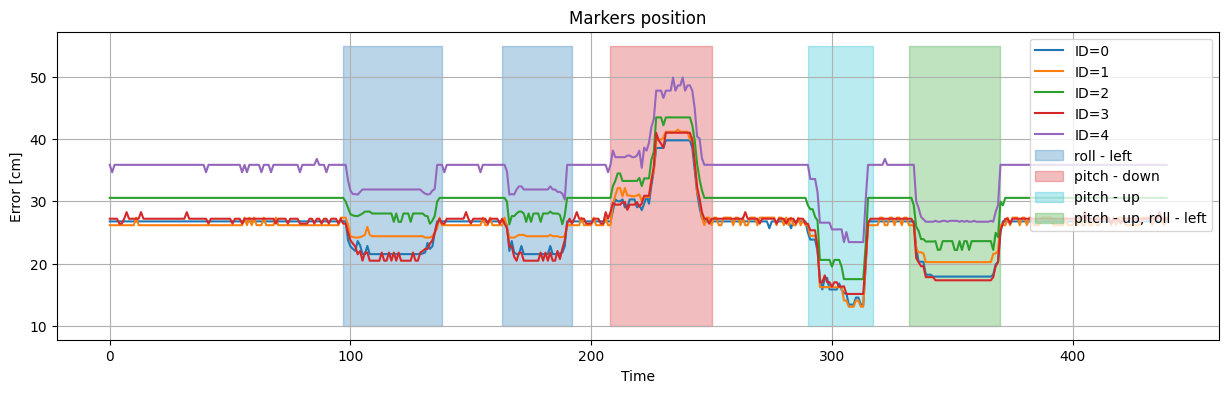

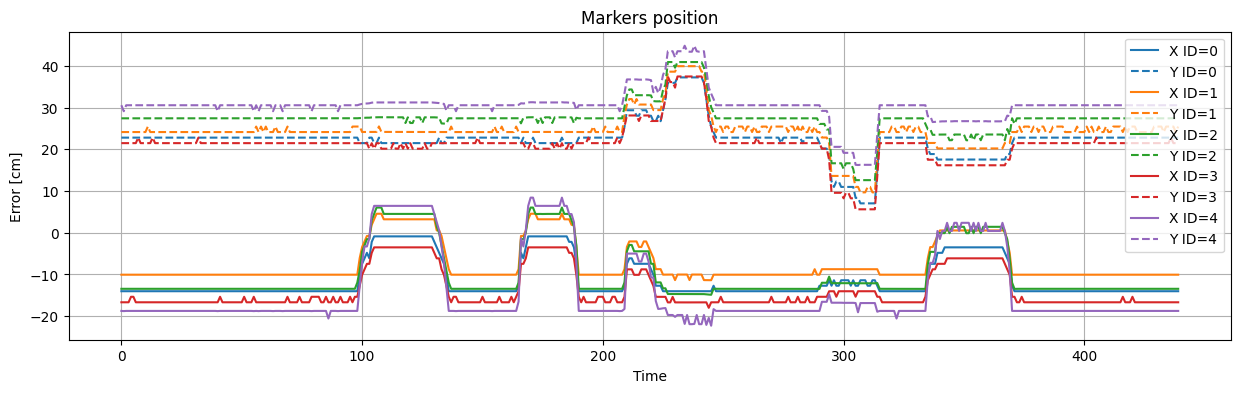

In [131]:
plt.figure(figsize=(15, 4))
for i in range(3):

    plt.plot(x, smoothed_rvecs[:,i], label=labels[i])

ymin = -6
ymax = 17

plt.fill_between([97, 138], [ymin, ymin], [ymax, ymax], alpha=0.3, color="tab:blue", label="roll - left")
plt.fill_between([163, 192], [ymin, ymin], [ymax, ymax], alpha=0.3, color="tab:blue")
plt.fill_between([208, 250], [ymin, ymin], [ymax, ymax], alpha=0.3, color="tab:red", label="pitch - down")
plt.fill_between([290, 317], [ymin, ymin], [ymax, ymax], alpha=0.3, color="tab:cyan", label="pitch - up")
plt.fill_between([332, 370], [ymin, ymin], [ymax, ymax], alpha=0.3, color="tab:green", label="pitch - up, roll - left")

plt.legend()
plt.grid()
plt.xlabel("Time")
plt.ylabel("Angle [deg]")
plt.title("Sensor orientation")


plt.figure(figsize=(15, 4))

colors = [
    "tab:blue",
    "tab:orange",
    "tab:green",
    "tab:red",
    "tab:purple"
]

errors = []
for i in range(5):
    x_error = -(gt_x_pos[i] - pos_vecs[:, i, 0])
    y_error = -(gt_y_pos[i] - pos_vecs[:, i, 1])
    errors.append(np.linalg.norm(np.stack([x_error, y_error]).T, axis=1))
    plt.plot(x_axis, errors[-1], c=colors[i], label=f"ID={i}")

ymin = 10
ymax = 55
plt.fill_between([97, 138], [ymin, ymin], [ymax, ymax], alpha=0.3, color="tab:blue", label="roll - left")
plt.fill_between([163, 192], [ymin, ymin], [ymax, ymax], alpha=0.3, color="tab:blue")
plt.fill_between([208, 250], [ymin, ymin], [ymax, ymax], alpha=0.3, color="tab:red", label="pitch - down")
plt.fill_between([290, 317], [ymin, ymin], [ymax, ymax], alpha=0.3, color="tab:cyan", label="pitch - up")
plt.fill_between([332, 370], [ymin, ymin], [ymax, ymax], alpha=0.3, color="tab:green", label="pitch - up, roll - left")


plt.legend()
plt.grid()
plt.xlabel("Time")
plt.ylabel("Error [cm]")
plt.title("Markers position")

plt.figure(figsize=(15, 4))
for i in range(5):
    x_error = -(gt_x_pos[i] - pos_vecs[:, i, 0])
    y_error = -(gt_y_pos[i] - pos_vecs[:, i, 1])

    plt.plot(x_axis, x_error, c=colors[i], label=f"X ID={i}")
    plt.plot(x_axis, y_error, "--",c=colors[i], label=f"Y ID={i}")


plt.legend()
plt.grid()
plt.xlabel("Time")
plt.ylabel("Error [cm]")
plt.title("Markers position")

In [75]:
np.corrcoef(pos_vecs[:-1, 0, 0], smoothed_rvecs[:, 0])[0, 1], \
    np.corrcoef(pos_vecs[:-1, 0, 0], smoothed_rvecs[:, 1])[0, 1], \
    np.corrcoef(pos_vecs[:-1, 0, 0], smoothed_rvecs[:, 2])[0, 1]

(0.2178482525944604, -0.20580017356381194, 0.6581075856333917)

In [76]:
np.corrcoef(pos_vecs[:-1, 0, 1], smoothed_rvecs[:, 0])[0, 1], \
    np.corrcoef(pos_vecs[:-1, 0, 1], smoothed_rvecs[:, 1])[0, 1], \
    np.corrcoef(pos_vecs[:-1, 0, 1], smoothed_rvecs[:, 2])[0, 1]

(-0.6699739729719228, 0.011312147086229454, 0.018628150083583178)

In [77]:
np.corrcoef(errors[0][:-1], smoothed_rvecs[:, 0])[0, 1], \
    np.corrcoef(errors[0][:-1], smoothed_rvecs[:, 1])[0, 1], \
    np.corrcoef(errors[0][:-1], smoothed_rvecs[:, 2])[0, 1]

(-0.6685658041963812, 0.05955985494098613, -0.2258910479287132)

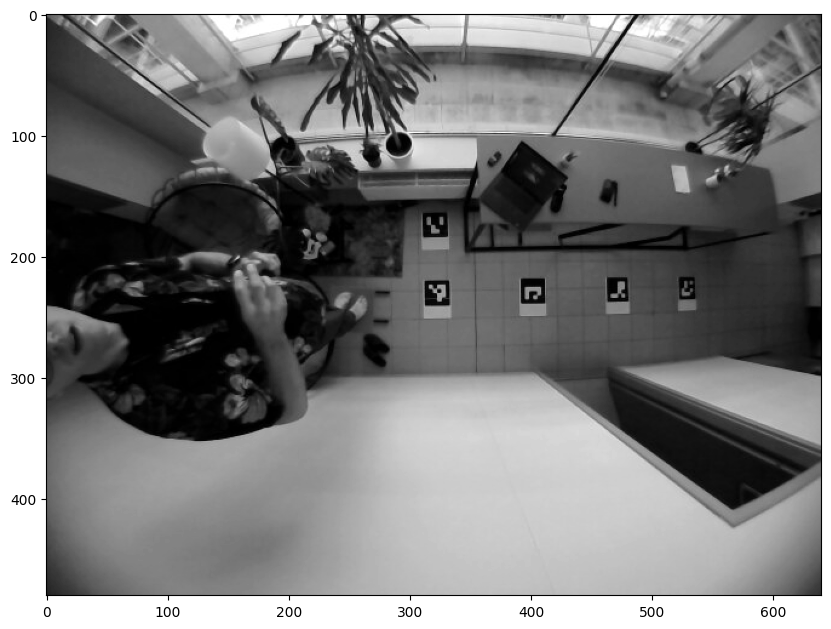

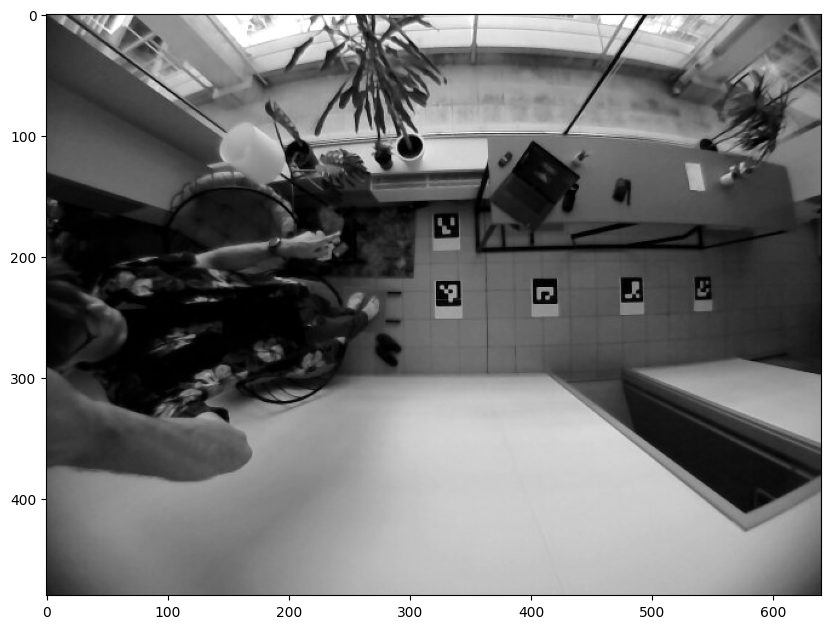

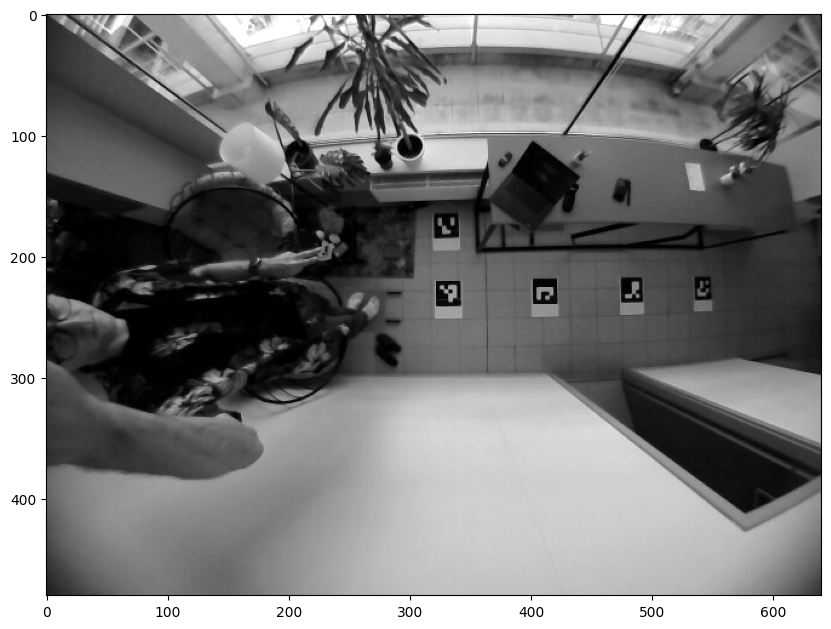

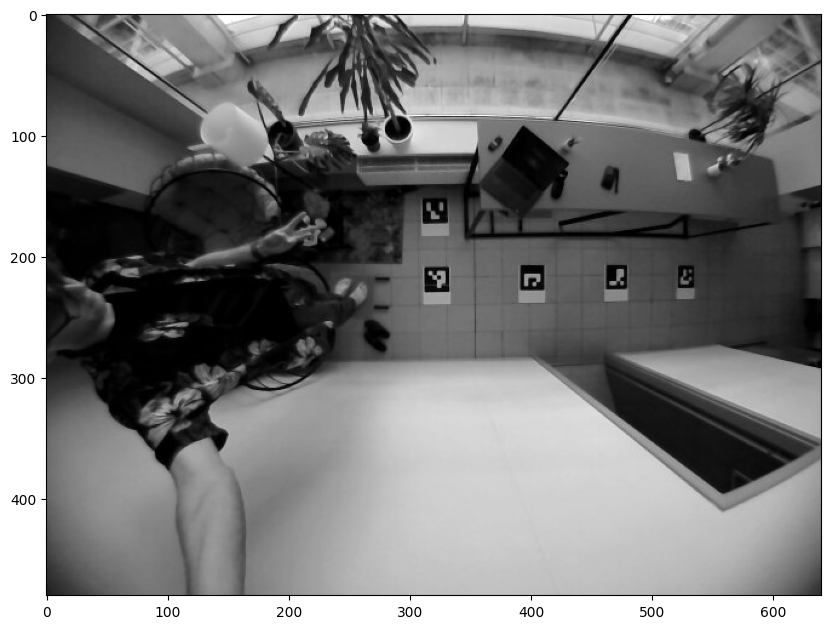

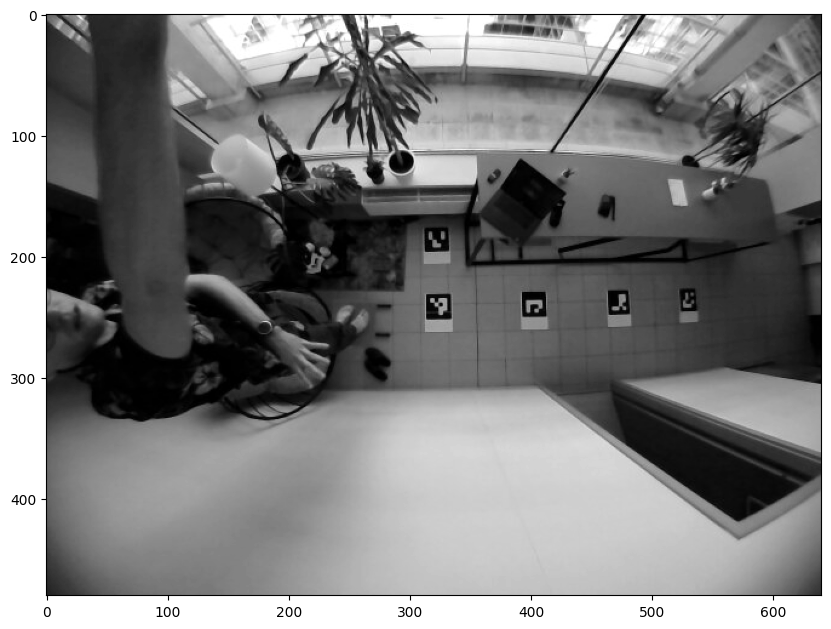

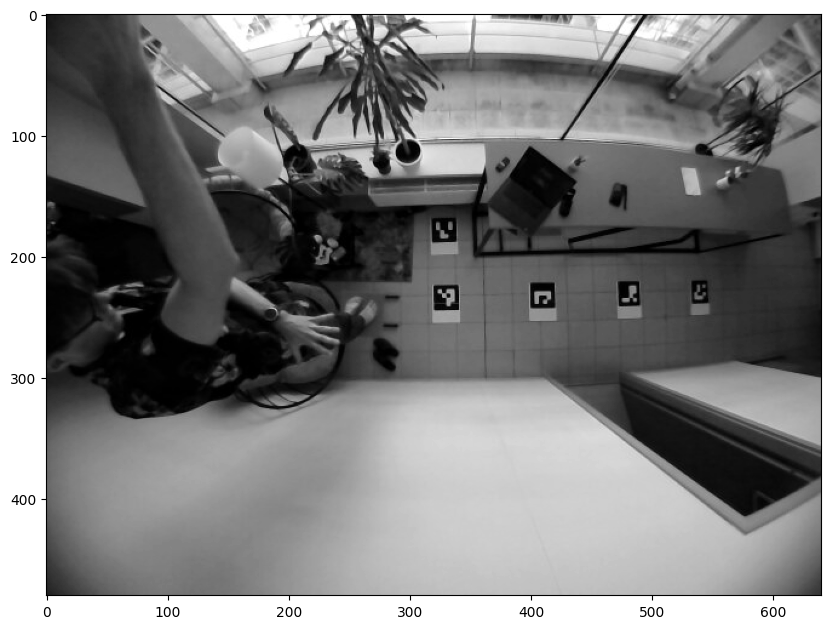

In [139]:
plt.figure(figsize=(10, 10))
plt.imshow(frames[70], cmap="gray")

plt.figure(figsize=(10, 10))
plt.imshow(frames[120], cmap="gray")

plt.figure(figsize=(10, 10))
plt.imshow(frames[180], cmap="gray")

plt.figure(figsize=(10, 10))
plt.imshow(frames[235], cmap="gray")

plt.figure(figsize=(10, 10))
plt.imshow(frames[305], cmap="gray")

plt.figure(figsize=(10, 10))
plt.imshow(frames[350], cmap="gray")